# 02 · Manifold — trajectory, root, pseudotime (Zhang et al. 2019)

Fit a cell-state trajectory on the whole malignant manifold. A **tree** diagnostic tests for a
Gast/pSom hub diverging into two arms; a **curve** is fit for the non-branching topology. The root
is placed at the **Gast/pSom-high developmental origin** (Gast/pSom are EARLY, Crest is LATE);
continuity is checked on an **independent diffusion-map embedding**, not off the UMAP being drawn.
Here the topology is robustly non-branching (2 tips, 0 forks across PPT settings; no Gast/pSom
co-expression hub), so a fold-free `curve` is fit. Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load the processed manifold; score modules; graph-smooth for geography
`score_genes` for Gast/pSom/Crest with the union control pool. The raw per-cell scores are the
honest readout (shown in the 03 deliverable panels); a light knn-connectivity smoothing (`_sm`) is
used only to read spatial geography and place the root — the raw scores in a 10x follicular-lymphoma
dataset are noise-dominated per cell (module means at control-pool baseline).

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells')
xy = adata.obsm['X_umap']
from numpy.linalg import svd
cc = xy - xy.mean(0); u,s,vt = svd(cc, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.dropna().drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('global raw module means:', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

whole malignant manifold: 5645 cells
UMAP aspect ratio (major/minor std): 1.64
Gast: 57/81 genes present
pSom: 60/98 genes present
Crest: 81/104 genes present
global raw module means: {'Gast': 0.0117, 'pSom': 0.0062, 'Crest': 0.0092}


### Module geography and compartment relationship
Whole-manifold smoothed module correlations and per-compartment means. Gast and pSom are spatially
**anti-correlated** (no co-expression hub), and both oppose Crest. The developmental axis runs
across both the cycling and non-cycling compartments (orthogonal to the proliferation split), so
the whole manifold is the trajectory object — no scoping to a single lobe.

In [4]:
print('smoothed spatial correlations on the whole manifold:')
for a_,b_ in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a_], adata.obs[b_])[0,1]; print(f'  {a_} vs {b_}: r = {r:+.2f}')
print('\nper-compartment smoothed developmental means:')
print(adata.obs.groupby('compartment', observed=True)[['Gast_sm','pSom_sm','Crest_sm']].mean().round(4).to_string())
g = adata.obs['Gast_sm'].values; p = adata.obs['pSom_sm'].values
both_hi = (g >= np.quantile(g,0.75)) & (p >= np.quantile(p,0.75))
print(f'\ncells high in BOTH Gast & pSom (>75th pct): {int(both_hi.sum())} of {adata.n_obs} '
      f'({100*both_hi.mean():.1f}%) -> no Gast/pSom co-expression hub')
sub = adata

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = -0.18
  Crest_sm vs Gast_sm: r = -0.54
  Crest_sm vs pSom_sm: r = -0.60

per-compartment smoothed developmental means:
             Gast_sm  pSom_sm  Crest_sm
compartment                            
Cycling       0.0014   0.0336   -0.0048
Non-cycling   0.0106   0.0036    0.0120

cells high in BOTH Gast & pSom (>75th pct): 698 of 5645 (12.4%) -> no Gast/pSom co-expression hub


### Topology — tree diagnostic then curve fit
A PPT tree is fit first to test for a Gast/pSom hub diverging into a distinct Gast arm. Across a
grid of `Nodes` and `ppt_lambda` the graph is essentially a strip (2 tips, 0 forks). Spurious single
forks appear only under the loosest regularization (`ppt_lambda=50` at Nodes=20/50) or heaviest
overfitting (Nodes=50, ~1 node per 113 cells, also at `ppt_lambda=100`); they disappear at
`ppt_lambda=300`, and the canonical fit (Nodes=20, `ppt_lambda>=100`) together with every curve fit
give 2 tips, 0 forks. Absent a fork with opposing Gast/pSom arms, the topology is non-branching and a
`curve` is fit. Fold-freeness is checked by the graph self-approach ratio (>1 = no fold-back) across
`Nodes` settings.

In [5]:
print('PPT tree branching probe (tips / forks across settings):')
for Nn in [15, 20, 30, 50]:
    for lam in [50, 100, 300]:
        ad = sub.copy(); sig = 0.1*np.ptp(ad.obsm['X_umap'])
        with contextlib.redirect_stdout(io.StringIO()):
            scf.tl.tree(ad, Nodes=Nn, use_rep='X_umap', method='ppt', ppt_lambda=lam,
                        ppt_sigma=sig, seed=SEED, plot=False)
        B = np.asarray(ad.uns['graph']['B']); deg = (B>0).sum(0)
        print(f'  Nodes={Nn:3d} lambda={lam:4d}: tips={int((deg==1).sum())} forks={int((deg>=3).sum())}')
# inspect tip biology on the canonical Nodes=20 tree
ad_t = sub.copy(); sig0 = 0.1*np.ptp(ad_t.obsm['X_umap'])
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(ad_t, Nodes=20, use_rep='X_umap', method='ppt', ppt_lambda=100, ppt_sigma=sig0, seed=SEED, plot=False)
Bt = np.asarray(ad_t.uns['graph']['B']); degt = (Bt>0).sum(0)
tips_t = np.where(degt==1)[0]
Dt = shortest_path(sp.csr_matrix((Bt>0).astype(int)), unweighted=True)
hard_t = np.asarray(ad_t.obsm['X_R']).argmax(1)
print('canonical Nodes=20 tree tip biology:')
for t in tips_t:
    m = np.isin(hard_t, np.where(Dt[t]<=2)[0])
    print(f'  tip{t}: n={int(m.sum()):5d} Gast={sub.obs["Gast_sm"][m].mean():+.4f} '
          f'pSom={sub.obs["pSom_sm"][m].mean():+.4f} Crest={sub.obs["Crest_sm"][m].mean():+.4f}')
print('no Gast/pSom co-expression hub with opposing arms -> non-branching (fit a curve).')

PPT tree branching probe (tips / forks across settings):
  Nodes= 15 lambda=  50: tips=2 forks=0
  Nodes= 15 lambda= 100: tips=2 forks=0
  Nodes= 15 lambda= 300: tips=2 forks=0
  Nodes= 20 lambda=  50: tips=3 forks=1
  Nodes= 20 lambda= 100: tips=2 forks=0
  Nodes= 20 lambda= 300: tips=2 forks=0
  Nodes= 30 lambda=  50: tips=2 forks=0
  Nodes= 30 lambda= 100: tips=2 forks=0
  Nodes= 30 lambda= 300: tips=2 forks=0
  Nodes= 50 lambda=  50: tips=3 forks=1
  Nodes= 50 lambda= 100: tips=3 forks=1
  Nodes= 50 lambda= 300: tips=2 forks=0
canonical Nodes=20 tree tip biology:
  tip17: n= 1346 Gast=+0.0158 pSom=+0.0035 Crest=+0.0066
  tip18: n= 1027 Gast=+0.0095 pSom=+0.0119 Crest=+0.0101
no Gast/pSom co-expression hub with opposing arms -> non-branching (fit a curve).


In [6]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks
for Nn in [15, 20, 30]:
    a2 = sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(a2, Nodes=Nn, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa, tips, forks = fold_diag(a2)
    print(f'curve N={Nn}: {tips} tips, {forks} forks | self-approach {sa:.2f}')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'chosen curve N=20: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, "topology check failed"

curve N=15: 2 tips, 0 forks | self-approach 2.99
curve N=20: 2 tips, 0 forks | self-approach 2.97
curve N=30: 2 tips, 0 forks | self-approach 2.68
chosen curve N=20: 2 tips, 0 forks | fold self-approach ratio = 2.97 (>1 = fold-free)


### Root at the Gast/pSom-high developmental origin; pseudotime
Score each curve tip by `Gast_sm + pSom_sm - Crest_sm`; root at the argmax (developmental origin,
Gast/pSom EARLY vs Crest LATE). Pseudotime gradients confirm Gast falls and Crest rises along the
axis, with the Crest-high decile toward the terminal end. A cycling-score correlation is reported as
an honest caveat — the axis is developmentally defined (root at the Gast-high pole), not
proliferation-driven (the confound analysis in the run notes shows Gast's decline survives
regressing out progression + interferon + proliferation).

In [7]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,pv = spearmanr(t, sub.obs[s]); print(f'  {s}: rho={rho:+.3f} p={pv:.1e}')
for m,lab_ in [('Crest_sm','Neural-crest'),('pSom_sm','Somitogenesis'),('Gast_sm','Gastrulation')]:
    hi = sub.obs[m] >= sub.obs[m].quantile(0.9)
    print(f'{lab_}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')
rho_p,_ = spearmanr(t, sub.obs['prolif_score'])
print(f'caveat: pseudotime vs proliferation-score rho = {rho_p:+.2f} (module gradient dominates; root at Gast-high pole)')

tip 0: Gast=+0.0093 pSom=+0.0112 Crest=+0.0106
tip 2: Gast=+0.0152 pSom=+0.0034 Crest=+0.0074
derived root = tip 2 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.510 p=0.0e+00
  pSom_sm: rho=+0.093 p=3.2e-12
  Crest_sm: rho=+0.324 p=1.8e-138
Neural-crest-high decile mean pseudotime = 0.56
Somitogenesis-high decile mean pseudotime = 0.83
Gastrulation-high decile mean pseudotime = 0.03
caveat: pseudotime vs proliferation-score rho = +0.11 (module gradient dominates; root at Gast-high pole)


### Continuity off an independent embedding (diffusion map)
Continuity is certified on a diffusion-map embedding computed independently of the UMAP being drawn
— a fold in the UMAP would not fool a metric built off a different embedding. A pseudotime that
tracks a single diffusion component (|corr| high) is a continuous 1-D axis; combined with the
fold-free self-approach ratio above, the curve is not folded.

In [8]:
sc.tl.diffmap(sub)
r_dc1 = abs(np.corrcoef(t, sub.obsm['X_diffmap'][:,1])[0,1])
r_dc2 = abs(np.corrcoef(t, sub.obsm['X_diffmap'][:,2])[0,1])
r_dc3 = abs(np.corrcoef(t, sub.obsm['X_diffmap'][:,3])[0,1])
print(f'|corr(pseudotime, DC1)| = {r_dc1:.2f} | DC2 = {r_dc2:.2f} | DC3 = {r_dc3:.2f}')
print(f'max diffusion-component alignment = {max(r_dc1,r_dc2,r_dc3):.2f} (fold-free self-approach = {sa:.2f})')
print('continuous 1-D axis on an independent embedding + fold-free curve -> no fold.')

|corr(pseudotime, DC1)| = 0.53 | DC2 = 0.74 | DC3 = 0.19
max diffusion-component alignment = 0.74 (fold-free self-approach = 2.97)
continuous 1-D axis on an independent embedding + fold-free curve -> no fold.


### House linear orientation (root at left) + curve overlay; save
Store an `X_umap_lin` layout with pseudotime increasing left->right so every downstream panel
(02/03/04) shares one orientation. `manifold.pdf` shows pseudotime with the fitted curve overlaid so
the topology is visible (not judged blind off a colour field). The ElPiGraph `uns['epg']` is reduced
to node positions so the object serializes.

orientation: corr(x_lin, pseudotime) = +0.76 (root at left)
saved manifold.h5ad + manifold.pdf


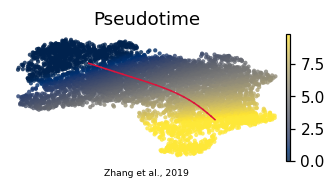

In [9]:
xy = sub.obsm['X_umap'].copy()
xyr = np.column_stack([xy[:,0], xy[:,1]])
r = float(np.corrcoef(xyr[:,0], t)[0,1])
if r < 0:
    xyr[:,0] = -xyr[:,0]; r = -r
assert r > 0, f'pseudotime not left->right (corr={r:+.2f})'
sub.obsm['X_umap_lin'] = xyr
print(f'orientation: corr(x_lin, pseudotime) = {r:+.2f} (root at left)')
# curve node coords in the linear layout for overlay
F = sub.uns['graph']['F'].T.copy(); Bc = np.asarray(sub.uns['graph']['B'])
Flin = F.copy(); 
if float(np.corrcoef(sub.obsm['X_umap'][:,0], t)[0,1]) < 0: Flin[:,0] = -Flin[:,0]
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ii,jj = np.where(np.triu(Bc>0))
for i,j in zip(ii,jj):
    ax.plot([Flin[i,0],Flin[j,0]], [Flin[i,1],Flin[j,1]], '-', color='crimson', lw=1.0, zorder=5)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Zhang et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')